## Project Title

**AI Customer Support Chatbot Using LSTM Deep Learning**

### Project Overview

This project develops an **AI-powered customer support chatbot** using **Deep Learning and LSTM (Long Short-Term Memory)**. The chatbot is trained using the **Bitext Customer Support Chatbot dataset** from Hugging Face, which contains customer questions, intents, and corresponding responses.

The user's message is first converted into numerical sequences using **tokenization and padding**. These sequences are then passed to an **LSTM neural network**, which learns patterns in customer queries and predicts the appropriate **customer-support intent**. Based on the predicted intent, the chatbot provides a suitable response.

### Technologies Used

* **Python**
* **Jupyter Notebook**
* **TensorFlow / Keras**
* **LSTM**
* **NumPy**
* **Pandas**
* **Scikit-learn**
* **Hugging Face Dataset**
* **Matplotlib**

### Working

```text
User Question
      ↓
Text Preprocessing
      ↓
Tokenization
      ↓
Padding
      ↓
Embedding Layer
      ↓
LSTM
      ↓
Intent Classification
      ↓
Select Response
      ↓
Chatbot Response
```

### Main Objective

The main objective is to build a chatbot that can **understand customer-support questions, classify their intent using an LSTM model, and provide an appropriate response automatically**.

### Example

```text
User:
I want to cancel my order.

        ↓

LSTM Model

        ↓

Predicted Intent:
cancel_order

        ↓

Bot:
Your request to cancel the order has been understood.
```

### Dataset

**Bitext Customer Support LLM Chatbot Training Dataset**

* **26,872** customer-support examples
* **27 intents**
* Contains user instructions/questions and responses
* Loaded directly using Hugging Face `datasets`

### Final Project Output

The project will produce:

1. Trained **LSTM chatbot model**
2. Training and validation accuracy graphs
3. Training and validation loss graphs
4. Intent prediction system
5. Interactive chatbot testing in Jupyter Notebook
6. Saved `.keras` model
7. Saved tokenizer and label encoder


In [2]:
# importing libaries

In [3]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
ds = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
)

ds

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

C:\Users\Dell\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dell\.cache\huggingface\hub\datasets--bitext--Bitext-customer-support-llm-chatbot-training-dataset. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Dell\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: User

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})

In [5]:
df = ds["train"].to_pandas()

df.head()

,flags,instruction,category,intent,response
0,B,question about cancelling order {{Order Number}},ORDER,cancel_order,I've understood you have a question regarding ...
1,BQZ,i have a question about cancelling oorder {{Or...,ORDER,cancel_order,I've been informed that you have a question ab...
2,BLQZ,i need help cancelling puchase {{Order Number}},ORDER,cancel_order,I can sense that you're seeking assistance wit...
3,BL,I need to cancel purchase {{Order Number}},ORDER,cancel_order,I understood that you need assistance with can...
4,BCELN,"I cannot afford this order, cancel purchase {{...",ORDER,cancel_order,I'm sensitive to the fact that you're facing f...


In [6]:
df.columns

Index(['flags', 'instruction', 'category', 'intent', 'response'], dtype='object')

In [7]:
len(df)

26872

In [8]:
print("Columns:", df.columns.tolist())

Columns: ['flags', 'instruction', 'category', 'intent', 'response']


In [9]:
df.isnull().sum()

flags          0
instruction    0
category       0
intent         0
response       0
dtype: int64

In [10]:
print(df["intent"].unique())

['cancel_order' 'change_order' 'change_shipping_address'
 'check_cancellation_fee' 'check_invoice' 'check_payment_methods'
 'check_refund_policy' 'complaint' 'contact_customer_service'
 'contact_human_agent' 'create_account' 'delete_account'
 'delivery_options' 'delivery_period' 'edit_account' 'get_invoice'
 'get_refund' 'newsletter_subscription' 'payment_issue' 'place_order'
 'recover_password' 'registration_problems' 'review'
 'set_up_shipping_address' 'switch_account' 'track_order' 'track_refund']


In [11]:
print("Number of intents:", df["intent"].nunique())

Number of intents: 27


In [12]:
df["intent"].value_counts()

intent
edit_account                1000
switch_account              1000
check_invoice               1000
complaint                   1000
contact_customer_service    1000
delivery_period              999
registration_problems        999
check_payment_methods        999
contact_human_agent          999
payment_issue                999
newsletter_subscription      999
get_invoice                  999
place_order                  998
cancel_order                 998
track_refund                 998
change_order                 997
get_refund                   997
create_account               997
check_refund_policy          997
review                       997
set_up_shipping_address      997
delivery_options             995
delete_account               995
recover_password             995
track_order                  995
change_shipping_address      973
check_cancellation_fee       950
Name: count, dtype: int64

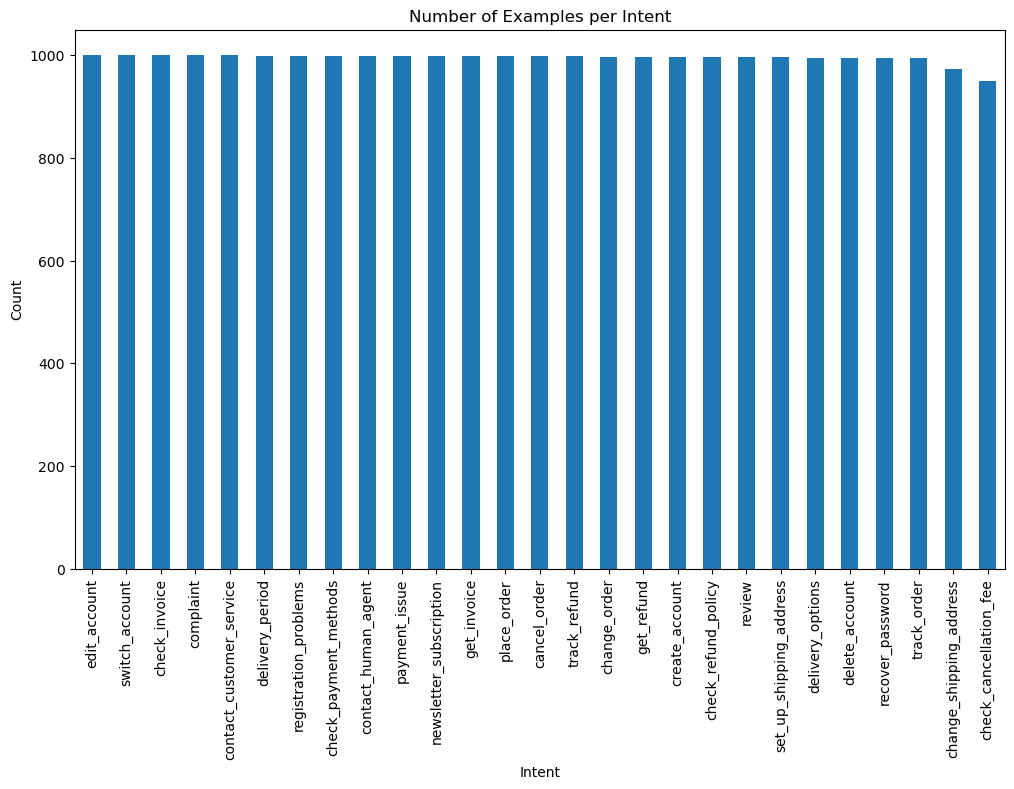

In [13]:
plt.figure(figsize=(12, 7))

df["intent"].value_counts().plot(kind="bar")

plt.title("Number of Examples per Intent")
plt.xlabel("Intent")
plt.ylabel("Count")
plt.xticks(rotation=90)

plt.show()

In [14]:
X = df["instruction"].astype(str).values
y = df["intent"].astype(str).values

In [17]:
print(X[0])

question about cancelling order {{Order Number}}


In [18]:
y[0]

'cancel_order'

In [19]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print(y_encoded[:10])

[0 0 0 0 0 0 0 0 0 0]


In [20]:
for i, intent in enumerate(label_encoder.classes_):
    print(i, "=", intent)

0 = cancel_order
1 = change_order
2 = change_shipping_address
3 = check_cancellation_fee
4 = check_invoice
5 = check_payment_methods
6 = check_refund_policy
7 = complaint
8 = contact_customer_service
9 = contact_human_agent
10 = create_account
11 = delete_account
12 = delivery_options
13 = delivery_period
14 = edit_account
15 = get_invoice
16 = get_refund
17 = newsletter_subscription
18 = payment_issue
19 = place_order
20 = recover_password
21 = registration_problems
22 = review
23 = set_up_shipping_address
24 = switch_account
25 = track_order
26 = track_refund


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 21497
Testing samples: 5375


In [22]:
tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

In [23]:
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)

Vocabulary size: 2566


In [24]:
X_train_sequences = tokenizer.texts_to_sequences(X_train)
X_test_sequences = tokenizer.texts_to_sequences(X_test)

In [25]:
X_train[0]

'I want assistance informing of a trouble with payment'

In [26]:
X_test_sequences[0]

[13, 19, 3, 86, 80, 23, 115, 118]

In [27]:
MAX_LENGTH = 30

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

In [28]:
X_train_padded.shape

(21497, 30)

In [29]:
X_test_padded.shape

(5375, 30)

In [32]:
num_classes = len(label_encoder.classes_)

model = Sequential([
    tf.keras.Input(shape=(MAX_LENGTH,)),
    
    Embedding(
        input_dim=10000,
        output_dim=128
    ),
    
    LSTM(128),
    
    Dropout(0.5),
    
    Dense(
        num_classes,
        activation="softmax"
    )
])

In [33]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ (None, 30, 128)             │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 27)                  │           3,483 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,415,067 (5.40 MB)

 Trainable params: 1,415,067 (5.40 MB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [35]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_padded,
    y_train,
    validation_split=0.1,
    epochs=20,
    batch_size=64,
    callbacks=[early_stop]
)

Epoch 1/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.2641 - loss: 2.1450 - val_accuracy: 0.5767 - val_loss: 1.0818
Epoch 2/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.7095 - loss: 0.7437 - val_accuracy: 0.8260 - val_loss: 0.4617
Epoch 3/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.8572 - loss: 0.3979 - val_accuracy: 0.8833 - val_loss: 0.3831
Epoch 4/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 12s 39ms/step - accuracy: 0.9424 - loss: 0.2042 - val_accuracy: 0.9716 - val_loss: 0.1312
Epoch 5/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 13s 43ms/step - accuracy: 0.9729 - loss: 0.1144 - val_accuracy: 0.9721 - val_loss: 0.1297
Epoch 6/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.9782 - loss: 0.0985 - val_accuracy: 0.9800 - val_loss: 0.1004
Epoch 7/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 13s 42ms/step - accuracy: 0.9902 - loss: 0.0491 - val_accuracy: 0.9795 - val_loss: 0.1012
Epoch 8/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 12s 41ms/step - accuracy: 0.9910 - loss: 0.0482 - 

In [36]:
loss, accuracy = model.evaluate(
    X_test_padded,
    y_test
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

168/168 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9888 - loss: 0.0575
Test Loss: 0.057451121509075165
Test Accuracy: 0.9888371825218201


In [37]:
print("Test Accuracy:", accuracy * 100, "%")

Test Accuracy: 98.883718252182 %


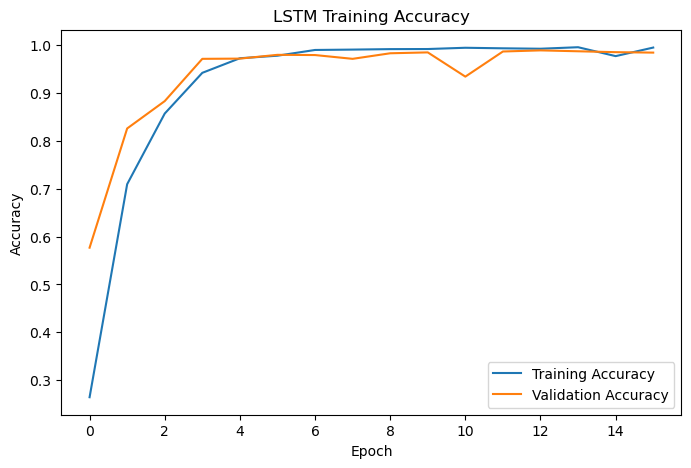

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("LSTM Training Accuracy")

plt.legend()
plt.show()

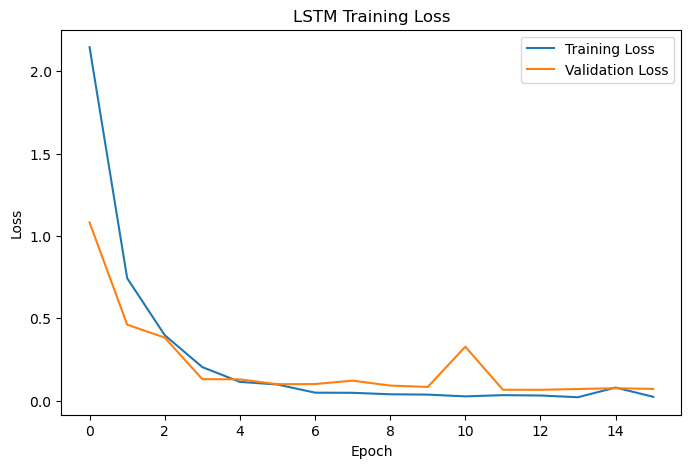

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training Loss")

plt.legend()
plt.show()

In [40]:
def predict_intent(text):

    sequence = tokenizer.texts_to_sequences([text])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )

    prediction = model.predict(padded, verbose=0)

    predicted_index = np.argmax(prediction)

    confidence = np.max(prediction)

    intent = label_encoder.inverse_transform(
        [predicted_index]
    )[0]

    return intent, confidence

In [42]:
text = "I want to Buy my product"

intent, confidence = predict_intent(text)

print("Input:", text)
print("Predicted Intent:", intent)
print("Confidence:", confidence)

Input: I want to Buy my product
Predicted Intent: place_order
Confidence: 0.99775606


In [43]:
test_questions = [
    "I want to cancel my order",
    "How can I get my invoice?",
    "I want to change my shipping address",
    "What payment methods do you accept?",
    "I want a refund",
    "I cannot make a payment",
    "I want to create an account"
]

for question in test_questions:

    intent, confidence = predict_intent(question)

    print("Question:", question)
    print("Intent:", intent)
    print("Confidence:", round(confidence, 4))
    print("-" * 60)

Question: I want to cancel my order
Intent: cancel_order
Confidence: 0.999
------------------------------------------------------------
Question: How can I get my invoice?
Intent: get_invoice
Confidence: 0.9971
------------------------------------------------------------
Question: I want to change my shipping address
Intent: change_shipping_address
Confidence: 0.9982
------------------------------------------------------------
Question: What payment methods do you accept?
Intent: check_payment_methods
Confidence: 0.9997
------------------------------------------------------------
Question: I want a refund
Intent: get_refund
Confidence: 0.9975
------------------------------------------------------------
Question: I cannot make a payment
Intent: check_payment_methods
Confidence: 0.9359
------------------------------------------------------------
Question: I want to create an account
Intent: create_account
Confidence: 0.9994
------------------------------------------------------------


In [44]:
response_dict = {}

for intent in df["intent"].unique():

    responses = df[
        df["intent"] == intent
    ]["response"].tolist()

    response_dict[intent] = responses

In [45]:
import random

def chatbot(text):

    intent, confidence = predict_intent(text)

    if confidence < 0.50:
        return "Sorry, I don't understand your question."

    response = random.choice(
        response_dict[intent]
    )

    return response

In [46]:
question = "I need to cancel my order"

answer = chatbot(question)

print("You:", question)
print("Bot:", answer)

You: I need to cancel my order
Bot: I'm aware that you're seeking assistance with canceling your purchase with order number {{Order Number}}. I apologize for any inconvenience caused by this situation. Let's work together to resolve it quickly. Here's what you need to do:

1. Sign into Your Account: Log in to your {{Company Account}} using your credentials.
2. Locate Your Order: Navigate to the '{{Online Order Interaction}}' or '{{Online Order Interaction}}' section, where you can find a list of your recent purchases.
3. Find the Specific Purchase: Look for the purchase with the order number {{Order Number}}. Click on it to access the order details.
4. Initiate Cancellation: Within the order details page, you will see an option labeled '{{Online Order Interaction}}' or a similar expression. Please select this option.
5. Follow Any Additional Steps: The system might ask you to provide a reason for cancellation or confirm your decision. Please provide the necessary information or follow 

In [51]:
while True:

    user_input = input("You: ")

    if user_input.lower() in ["bye", "exit", "quit"]:
        print("Bot: Goodbye!")
        break

    response = chatbot(user_input)

    print("Bot:", response)

You:  hey


Bot: We're all ears! I'm tuned into the idea that you have the need to talk to an assistant. Our team of dedicated representatives is always ready to assist you. To connect you with the right person who can address your concerns, may I kindly ask for some additional details? What is the specific issue or question you would like assistance with? By understanding your needs, we can ensure that you receive the most relevant support. Thank you for your cooperation, and please wait a moment while I find the best assistant to help you.


KeyboardInterrupt: Interrupted by user

In [48]:
model.save("lstm_chatbot.keras")

In [49]:
import pickle

with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

In [50]:
with open("label_encoder.pkl", "wb") as file:
    pickle.dump(label_encoder, file)

In [52]:
with open("response_dict.pkl", "wb") as f:
    pickle.dump(response_dict, f)